Choose data mode:
1. Use built-in scenario
2. Enter Custom process info


Enter choice (1 or 2):  1


Running built-in example scenario...
Vertices: ['A', 'B', 'C', 'D', 'E']
Edges: [('A', 'B', 4), ('A', 'C', 2), ('B', 'C', 3), ('B', 'D', 2), ('B', 'E', 3), ('C', 'B', 1), ('C', 'D', 4), ('C', 'E', 5), ('D', 'E', 1)]
Route: From A to E
Congestion updates to apply: [('B', 'D', 10), ('C', 'B', 6)]

----------------------------------------
TRAFFIC ANALYSIS REPORT
----------------------------------------
Original Shortest Path: A -> C -> B -> E
Original Travel Cost: 6
----------------------------------------
Updated Shortest Path: A -> B -> E
Updated Travel Cost: 7
----------------------------------------
Traffic Impact: Travel cost increased by 1 units due to congestion.


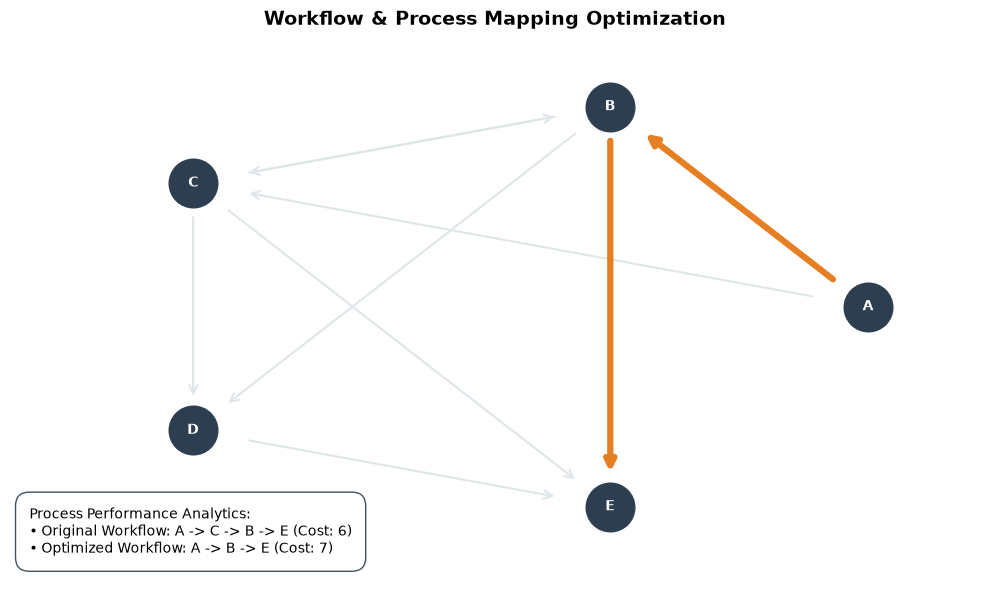

In [2]:
import sys
import matplotlib.pyplot as plt
import math

def bellman_ford(vertices, edges, start, end):
    distance = {v: float('inf') for v in vertices}
    parent = {v: None for v in vertices}
    distance[start] = 0
    
    for _ in range(len(vertices) - 1):
        for u, v, weight in edges:
            if distance[u] != float('inf') and distance[u] + weight < distance[v]:
                distance[v] = distance[u] + weight
                parent[v] = u
                
    for u, v, weight in edges:
        if distance[u] != float('inf') and distance[u] + weight < distance[v]:
            return None, float('inf')
            
    path = []
    curr = end
    while curr is not None:
        path.append(curr)
        curr = parent[curr]
    path.reverse()
    
    return path if distance[end] != float('inf') else None, distance[end]

def visualize_workflow_process(vertices, edges, orig_path, new_path, orig_cost, new_cost):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.set_title("Workflow & Process Mapping Optimization", fontsize=14, fontweight='bold')
    
    num_nodes = len(vertices)
    pos = {}
    for idx, node in enumerate(vertices):
        angle = 2 * math.pi * idx / num_nodes
        pos[node] = (math.cos(angle), math.sin(angle))
        
    for u, v, w in edges:
        if u not in pos or v not in pos:
            continue
        x1, y1 = pos[u]
        x2, y2 = pos[v]
        
        is_on_optimal = False
        if new_path:
            for i in range(len(new_path) - 1):
                if new_path[i] == u and new_path[i+1] == v:
                    is_on_optimal = True
                    break
                    
        if is_on_optimal:
            ecolor = '#e67e22'
            ewidth = 4.5
        else:
            ecolor = '#dfe6e9'
            ewidth = 1.5
            
        dx = x2 - x1
        dy = y2 - y1
        length = math.sqrt(dx*dx + dy*dy)
        if length > 0:
            ax.annotate("", xy=(x2 - 0.15*dx/length, y2 - 0.15*dy/length),
                        xytext=(x1 + 0.15*dx/length, y1 + 0.15*dy/length),
                        arrowprops=dict(arrowstyle="->", color=ecolor, lw=ewidth, mutation_scale=15))
            
    for node, (x, y) in pos.items():
        ax.plot(x, y, marker='o', markersize=35, color='#2c3e50', linestyle='None')
        ax.text(x, y, str(node), color='white', ha='center', va='center', fontweight='bold', fontsize=10)
        
    orig_path_str = " -> ".join(orig_path) if orig_path else "None"
    new_path_str = " -> ".join(new_path) if new_path else "None"
    
    info_text = f"Process Performance Analytics:\n• Original Workflow: {orig_path_str} (Cost: {orig_cost})\n• Optimized Workflow: {new_path_str} (Cost: {new_cost})"
    ax.text(0.02, 0.05, info_text, transform=ax.transAxes,
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='#2c3e50', boxstyle='round,pad=1'))
            
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

def get_custom_input():
    vertices = input("Enter all vertices separated by spaces: ").split()
    edges = []
    print("Enter edges format 'source destination weight' (type 'done' to finish):")
    while True:
        line = input()
        if line.lower() == 'done':
            break
        u, v, w = line.split()
        edges.append((u, v, float(w)))
    start = input("Enter start vertex: ")
    end = input("Enter end vertex: ")
    print("\nEnter congested edges to modify format 'source destination new_weight' (type 'done' to finish):")
    congested_edges = []
    while True:
        line = input()
        if line.lower() == 'done':
            break
        u, v, w = line.split()
        congested_edges.append((u, v, float(w)))
    return vertices, edges, start, end, congested_edges

def run_simulation():
    print("Choose data mode:")
    print("1. Use built-in scenario")
    print("2. Enter Custom process info")
    choice = input("Enter choice (1 or 2): ").strip()
    
    if choice == '2':
        vertices, edges, start, end, congested_edges = get_custom_input()
    else:
        vertices = ['A', 'B', 'C', 'D', 'E']
        edges = [
            ('A', 'B', 4),
            ('A', 'C', 2),
            ('B', 'C', 3),
            ('B', 'D', 2),
            ('B', 'E', 3),
            ('C', 'B', 1),
            ('C', 'D', 4),
            ('C', 'E', 5),
            ('D', 'E', 1)
        ]
        start = 'A'
        end = 'E'
        congested_edges = [('B', 'D', 10), ('C', 'B', 6)]
        print("Running built-in example scenario...")
        print(f"Vertices: {vertices}")
        print(f"Edges: {edges}")
        print(f"Route: From {start} to {end}")
        print(f"Congestion updates to apply: {congested_edges}\n")

    orig_path, orig_cost = bellman_ford(vertices, edges, start, end)
    
    updated_edges = []
    congestion_dict = {(u, v): w for u, v, w in congested_edges}
    for u, v, w in edges:
        if (u, v) in congestion_dict:
            updated_edges.append((u, v, congestion_dict[(u, v)]))
        else:
            updated_edges.append((u, v, w))
            
    new_path, new_cost = bellman_ford(vertices, updated_edges, start, end)
    
    print("-" * 40)
    print("TRAFFIC ANALYSIS REPORT")
    print("-" * 40)
    print(f"Original Shortest Path: {' -> '.join(orig_path) if orig_path else 'No Path'}")
    print(f"Original Travel Cost: {orig_cost}")
    print("-" * 40)
    print(f"Updated Shortest Path: {' -> '.join(new_path) if new_path else 'No Path'}")
    print(f"Updated Travel Cost: {new_cost}")
    print("-" * 40)
    
    if orig_cost != float('inf') and new_cost != float('inf'):
        cost_diff = new_cost - orig_cost
        if cost_diff > 0:
            print(f"Traffic Impact: Travel cost increased by {cost_diff} units due to congestion.")
        elif cost_diff < 0:
            print(f"Traffic Impact: Alternative routing optimized travel cost by {abs(cost_diff)} units.")
        else:
            print("Traffic Impact: Congestion did not affect the optimal travel route cost.")
    else:
        print("Traffic Impact: A valid route could not be sustained on one or both configurations.")
        
    visualize_workflow_process(vertices, updated_edges, orig_path, new_path, orig_cost, new_cost)

if __name__ == "__main__":
    run_simulation()